# TOAST Maploader

Author : Henry Nachman

---

A file to load filterbin maps after they have been made by TOAST

# Imports

In [1]:
import matplotlib.pyplot as plt
import os, sys
import pickle as pkl

abspath = os.path.dirname(os.path.abspath("toast_maploader.ipynb"))
fig_out_path = "/shared_home/henachman/home/SO_PointingReqs/output_analysis"
if abspath not in sys.path:
    sys.path.append(abspath)

from toast_fbmaploader import *

In [22]:
path_to_data = "/shared_home/henachman/data/sim_outputs/"

SSO = "Mars"
if SSO=="Mars":
    ra = 111.0992
    dec = 25.1832
if SSO=="Jupiter":
    ra = 72.4123427736188
    dec = 22.100098621604207
else:
    ra = 111.0992
    dec = 25.1832
rot = [ra, dec]


maps_dict = {}

In [23]:
print(maps_dict.keys())

dict_keys([])


In [27]:
def load_h5_map(path_to_job, path_to_data, hits=True):
    path_to_map = f"{path_to_data}{path_to_job}/filterbin_filtered_map.h5"
    with h5py.File(path_to_map, "r") as f:
        dset = f["map"]
        # nside = int(dset.attrs["NSIDE"])
        # nest = dset.attrs["ORDERING"] == "NESTED"
        I_map, Q_map, U_map = dset[0], dset[1], dset[2]          # stokes I; use dset[1], dset[2] for Q, U

    hits_map = None
    if hits==True:
        hitmap_path = f"{path_to_data}{path_to_job}/filterbin_filtered_hits.h5"
        with h5py.File(hitmap_path, "r") as f:
            dset = f["map"]
            hits_map = dset[0]

        unseen_mask = (hits_map == 0)
        for map in [I_map, Q_map, U_map]:
            map[hits_map == 0] = hp.UNSEEN    # blank the unhit pixels

    return I_map, Q_map, U_map, hits_map, unseen_mask

In [28]:
run_path = {
    # "plain" : "Mars/Mars_SSO_f090_261020_210359",
    "plain_CMB" : "CMB/Deep56_f090_261022_175547",
    "jitter_CMB" : "CMB/Deep56_jitter_f090_261022_194414"
    # "offset" : "Mars_SSO_offset_f090_261020_210407",
    # "jitter" : "Mars_SSO_jitter_f090_261020_210415",
    # "hd_plain" : "Mars_SSO_f090_261021_195858",
    # "hd_jitter" : "Mars_SSO_jitter_f090_261021_193527"
    }

for name, path in run_path.items():
    if name not in maps_dict:
        print(f"Adding {name}, {path}")
        I_map, _, _, hits_map, unseen_mask = load_h5_map(path, path_to_data=path_to_data)
        try:
            rot_est = get_center(I_map)
        except:
            rot_est = rot
        maps_dict[name] = {"I_map": I_map,
                           "hits_map": hits_map,
                           "rot_est": rot_est,
                           "path":path}

Adding plain_CMB, CMB/Deep56_f090_261022_175547


# SSO Maps

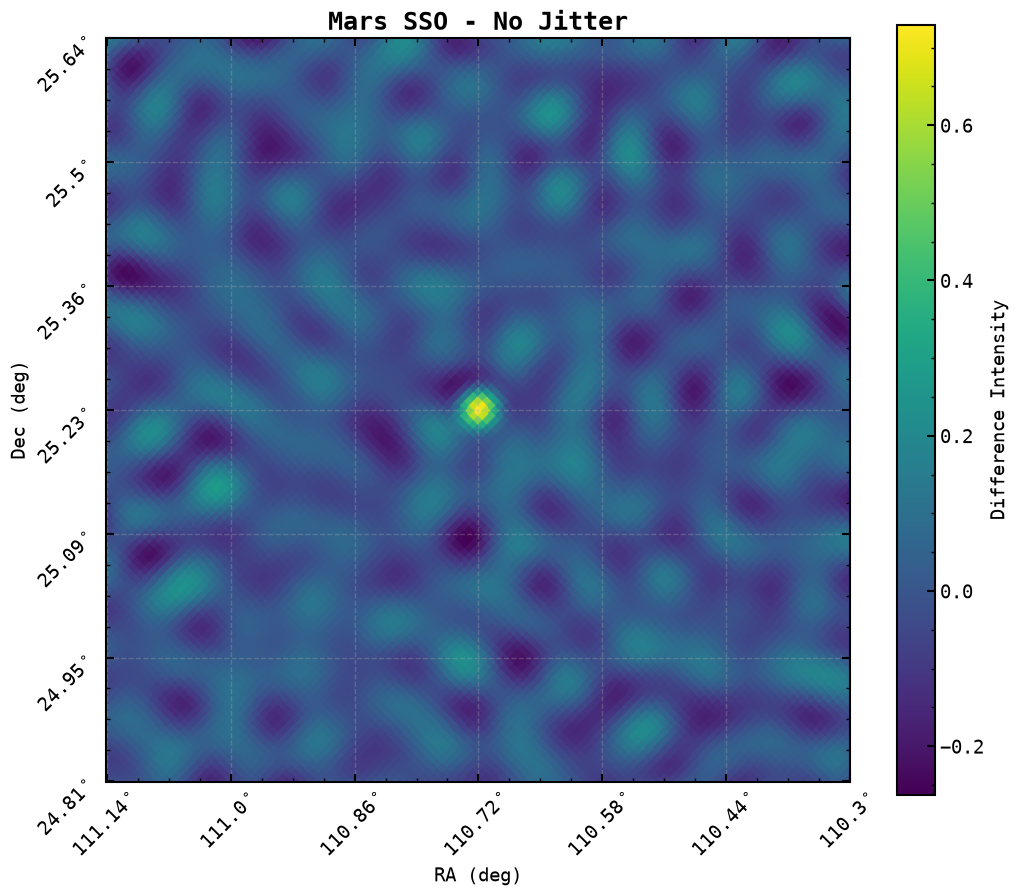

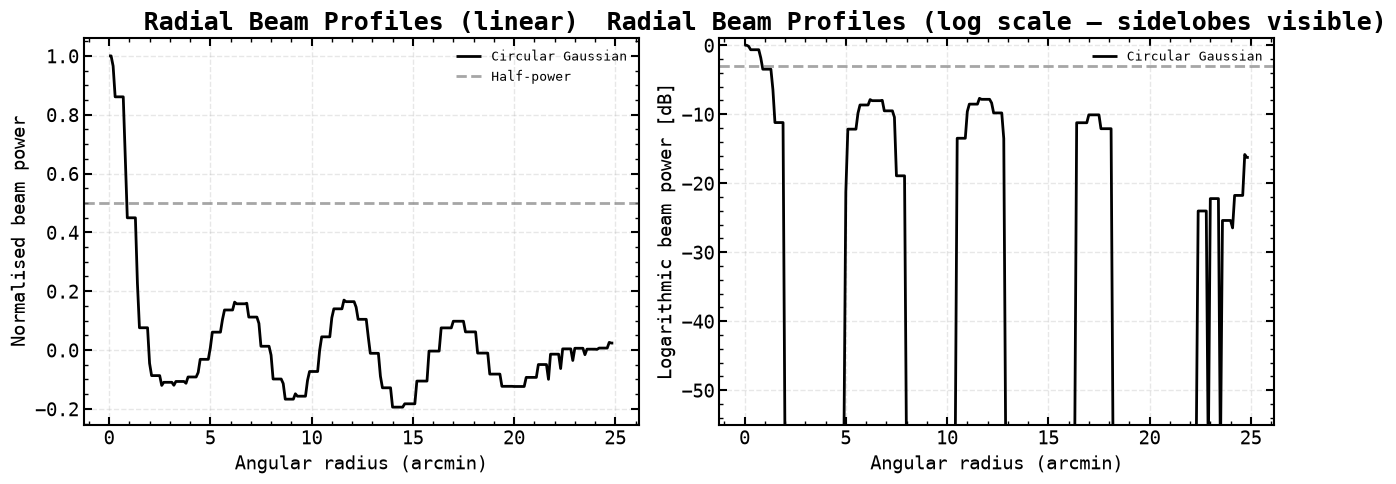

In [13]:
N = 500 # Num pix
pix_size = 0.1 # arcmin per pix

for map_name in ["plain"]: #maps_dict.keys():
    proj_map, _ = single_plot(maps_dict[map_name]["I_map"],
            rot=maps_dict[map_name]["rot_est"],
            xsize=N,
            reso=pix_size,
            cmap='viridis',
            show=False,
            hits = maps_dict[map_name]["hits_map"])
    # print(centroid_center(maps_dict[map_name]["map"], rot))
    plt.title("Mars SSO - No Jitter")
    plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)

    r_amin, profile = get_radial_profile(proj_map, N, pix_size, show=True)
    maps_dict[map_name]["profile"] = [r_amin, profile]

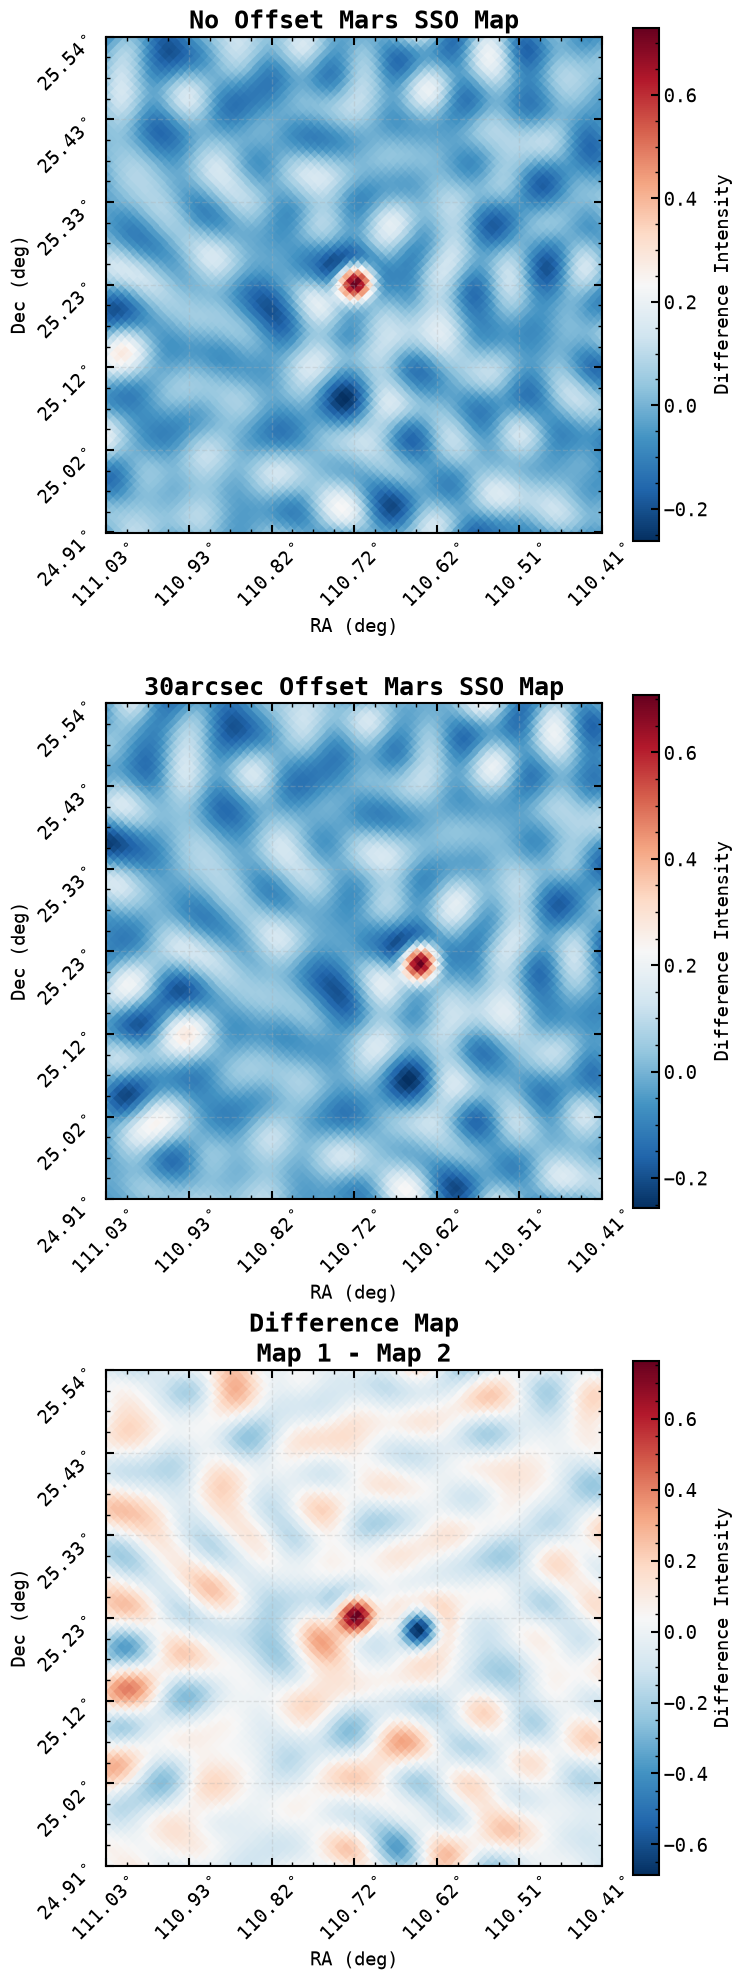

In [17]:
fig, axs = diff_plot(maps_dict["plain"]["I_map"],
          maps_dict["offset"]["I_map"],
          rot=maps_dict["plain"]["rot_est"],
          xsize=750,
          reso=0.05,
          deg=True,
          show=False,)

axs[0].set_title("No Offset Mars SSO Map")
axs[1].set_title("30arcsec Offset Mars SSO Map")
plt.savefig(os.path.join(fig_out_path, "Mars_offset_diff.png"))

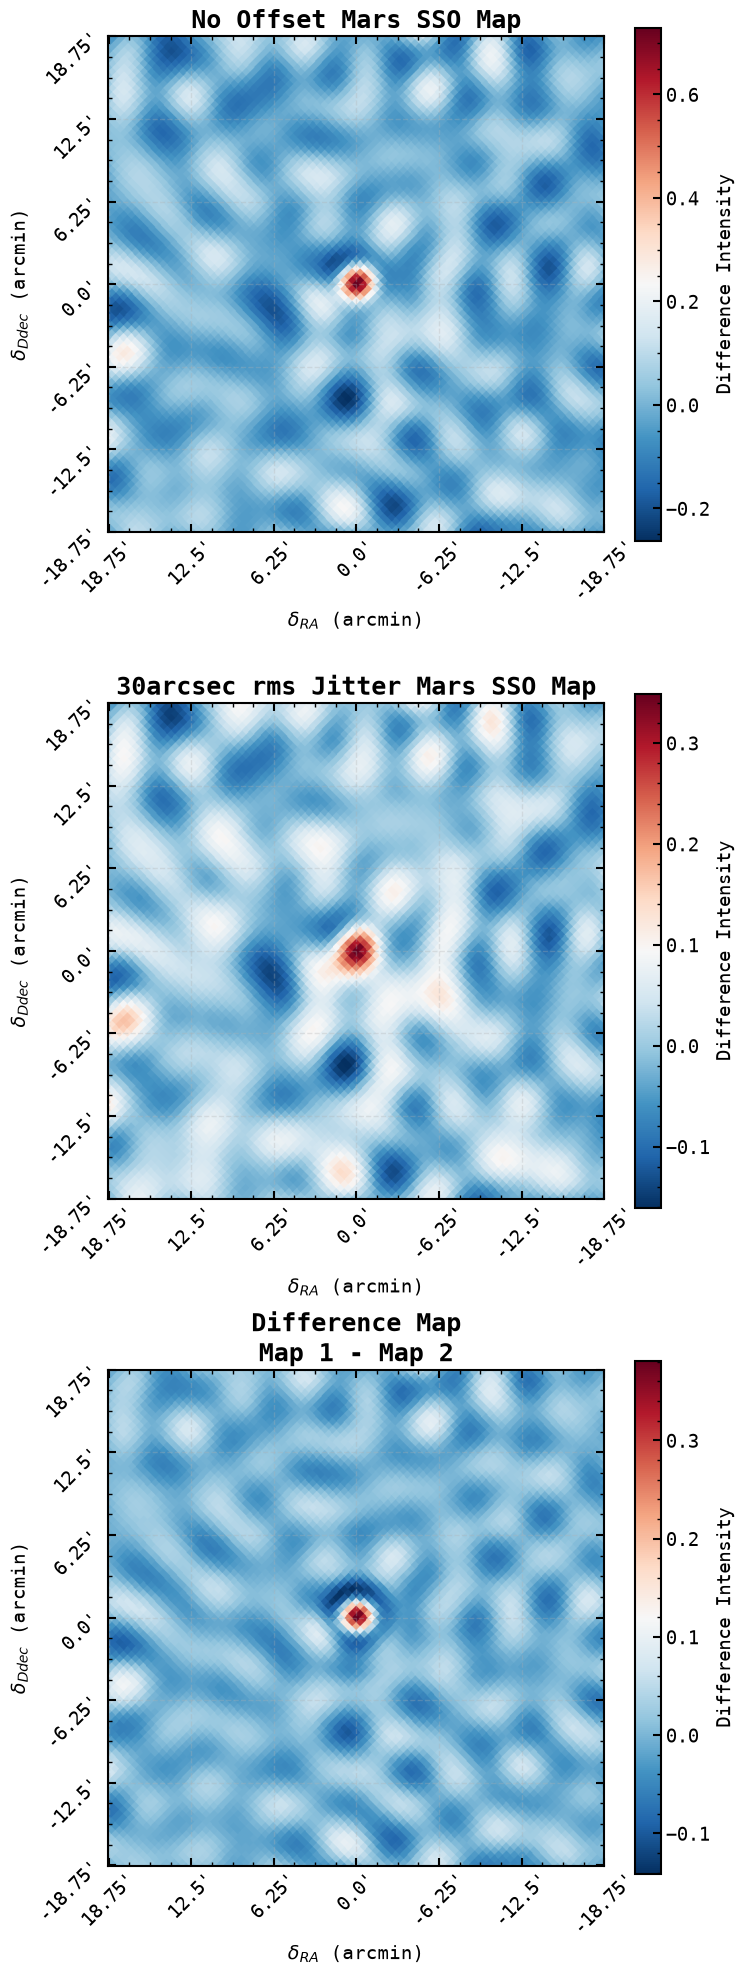

In [16]:
fig, axs = diff_plot(maps_dict["plain"]["I_map"],
          maps_dict["jitter"]["I_map"],
          rot=maps_dict["plain"]["rot_est"],
          xsize=750,
          reso=0.05,
          show=False,
          deg=False,)

axs[0].set_title("No Offset Mars SSO Map")
axs[1].set_title("30arcsec rms Jitter Mars SSO Map")
plt.savefig(os.path.join(fig_out_path, "Mars_jitter_diff.png"))

# CMB Maps

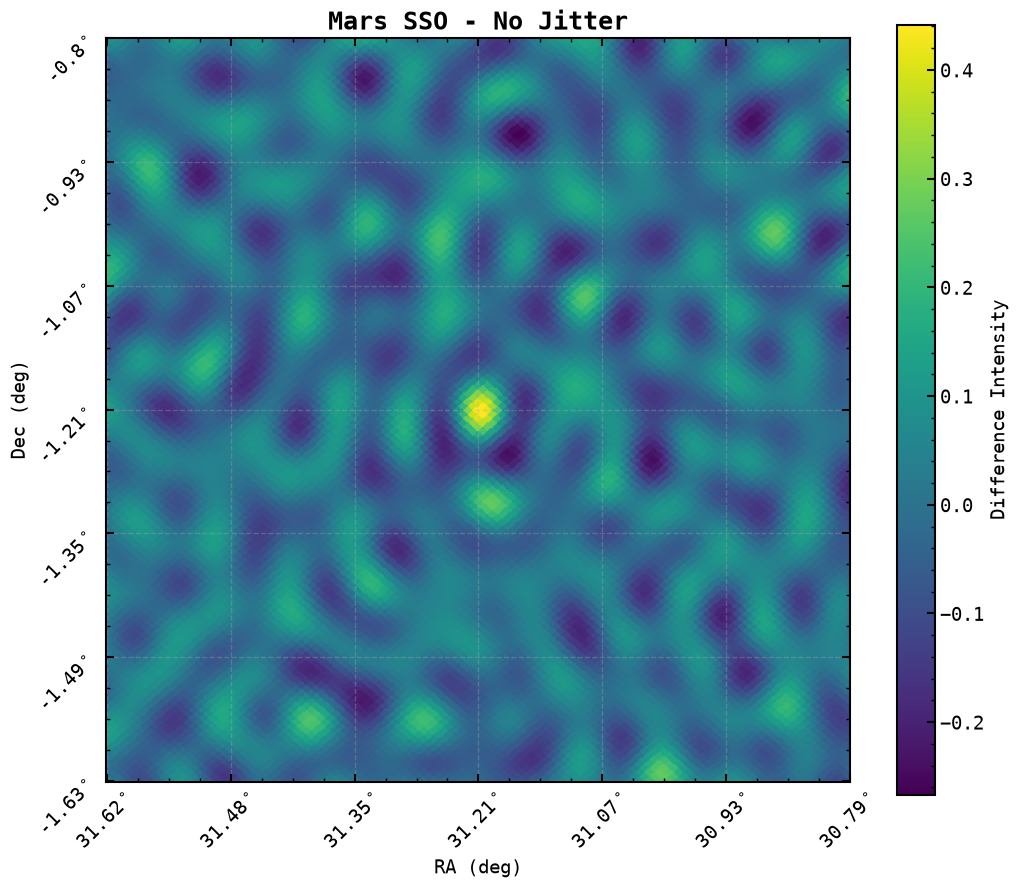

In [20]:
N = 500 # Num pix
pix_size = 0.1 # arcmin per pix

for map_name in ["plain_CMB"]: #maps_dict.keys():
    proj_map, _ = single_plot(maps_dict[map_name]["I_map"],
            rot=maps_dict[map_name]["rot_est"],
            xsize=N,
            reso=pix_size,
            cmap='viridis',
            show=False,
            hits = maps_dict[map_name]["hits_map"])
    # print(centroid_center(maps_dict[map_name]["map"], rot))
    plt.title("Mars SSO - No Jitter")
    plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)


Center of hits map: [16.06638859]°, [-1.28138353]°
Center of hits map: [16.06638859]°, [-1.28138353]°


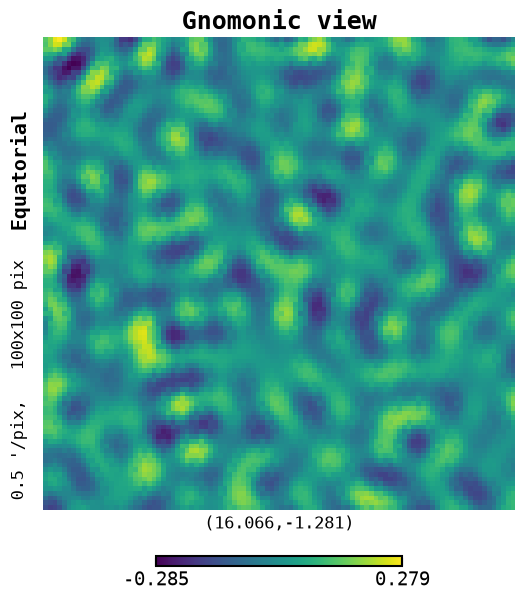

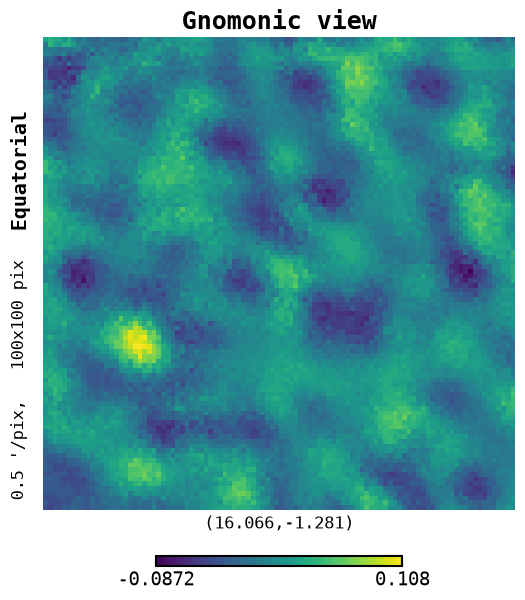

In [93]:

for map_name in ["plain_CMB", "jitter_CMB"]:
        rot = get_mol_center(maps_dict[map_name]["hits_map"])

        moll_map = hp.gnomview(
                maps_dict[map_name]["I_map"],
                coord='C',
                nest=True,
                rot = rot,
                xsize=100,
                ysize=100,
                reso=0.5,
                badcolor='gray',
                return_projected_map=True
        )

        maps_dict[map_name]["moll_map"] = moll_map

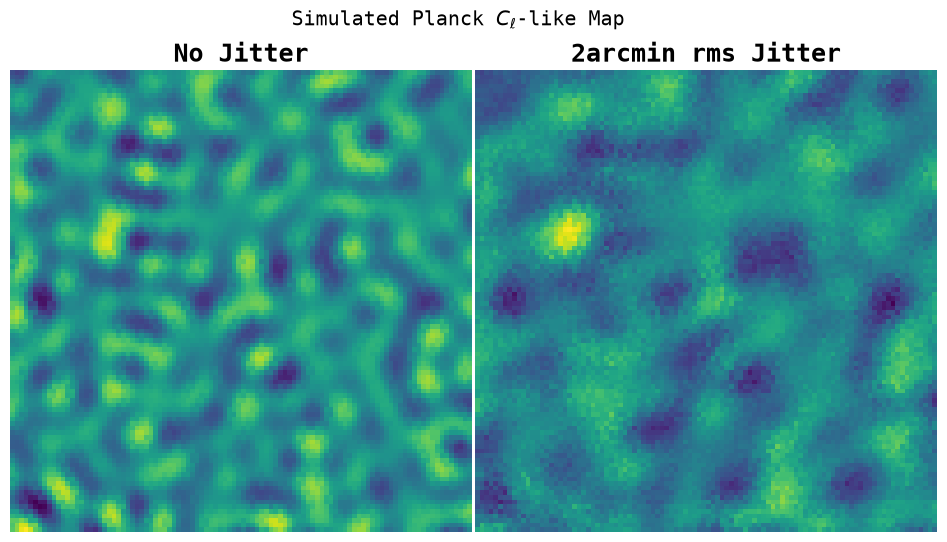

In [94]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
fig.subplots_adjust(wspace=0, hspace=0)
axs[0].imshow(maps_dict["plain_CMB"]["moll_map"])
# axs[0].set_xlim(0,100)
axs[0].axis('off')
axs[0].get_yaxis().set_visible(False)
axs[1].imshow(maps_dict["jitter_CMB"]["moll_map"])
axs[1].axis('off')
axs[1].get_yaxis().set_visible(False)
# axs[1].set_xlim(100,200)
plt.suptitle(r"Simulated Planck $C_\ell$-like Map")
axs[0].set_title("No Jitter")
axs[1].set_title("2arcmin rms Jitter")
fig.subplots_adjust(wspace=0, hspace=0)


In [67]:
def cosine_window(N):
    "makes a cosine window for apodizing to avoid edges effects in the 2d FFT" 
    # make a 2d coordinate system
    N=int(N) 
    ones = np.ones(N)
    inds  = (((np.arange(N)+.5 - N/2.)/N) *np.pi) ## eg runs from -pi/2 to pi/2
    X = np.outer(ones,inds)
    Y = np.transpose(X)
  
    # make a window map
    window_map = np.cos(X) * np.cos(Y)
   
    # return the window map
    return(window_map)
  ###############################

N = np.shape(maps_dict["plain_CMB"]["moll_map"])[0]
print(N)
window = (cosine_window(N))
    
apodized_map = window * maps_dict["plain_CMB"]["moll_map"]
apodized_jmap = window * maps_dict["jitter_CMB"]["moll_map"]

2000


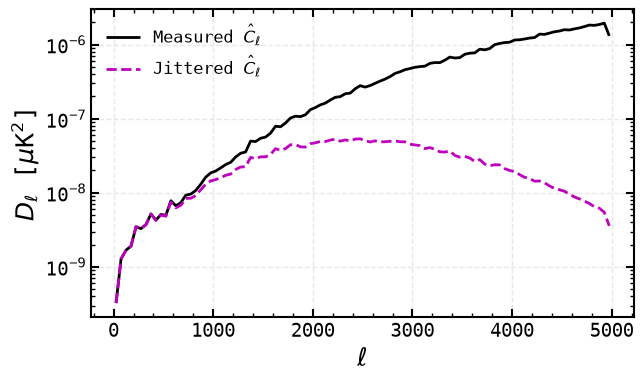

In [68]:
#### parameters for setting up the spectrum
delta_ell = 50.
# ell_min = 100.
ell_max = 5000.

# if max(ell)< ell_max: 
#     print('WARNING: Your theory curves end before the binned ell_max')

def calculate_2d_spectrum(Map1,Map2,delta_ell,ell_max,pix_size,N):
    "calcualtes the power spectrum of a 2d map by FFTing, squaring, and azimuthally averaging"
    ell_min = 0
    N=int(N)
    # make a 2d ell coordinate system
    ones = np.ones(N)
    inds  = (np.arange(N)+.5 - N/2.) /(N-1.)
    kX = np.outer(ones,inds) / (pix_size/60. * np.pi/180.)
    kY = np.transpose(kX)
    K = np.sqrt(kX**2. + kY**2.)
    ell_scale_factor = 2. * np.pi 
    ell2d = K * ell_scale_factor
    
    # make an array to hold the power spectrum results
    N_bins = int((ell_max-ell_min)/delta_ell)
    ell_array = np.arange(N_bins)
    CL_array = np.zeros(N_bins)
    
    # get the 2d fourier transform of the map
    FMap1 = np.fft.ifft2(np.fft.fftshift(Map1))
    FMap2 = np.fft.ifft2(np.fft.fftshift(Map2))
    PSMap = np.fft.fftshift(np.real(np.conj(FMap1) * FMap2))
    # fill out the spectra

    for i in range(N_bins):
        ell_array[i] = (i + 0.5) * delta_ell + ell_min
        inds_in_bin = ((ell2d >= (i*delta_ell  + ell_min)) * (ell2d < ((i+1)* delta_ell + ell_min))).nonzero()
        CL_array[i] = np.mean(PSMap[inds_in_bin])

    # return the power spectrum and ell bins
    return(ell_array,CL_array*(pix_size /60.* np.pi/180.) /4)

## make a power spectrum
binned_ell, binned_spectrum = calculate_2d_spectrum(apodized_map,apodized_map,delta_ell,ell_max,0.5,N)
binned_jell, binned_jspectrum = calculate_2d_spectrum(apodized_jmap, apodized_jmap, delta_ell,ell_max,0.5,N)
# to go from Cl to Dl
fac_binned = binned_ell * (binned_ell+1.) /2. / np.pi
fac_jbinned = binned_jell * (binned_jell+1.) /2. / np.pi


fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(binned_ell,binned_spectrum* fac_binned, label=r"Measured $\hat{C}_\ell$")
ax.plot(binned_jell,binned_jspectrum* fac_jbinned, label=r"Jittered $\hat{C}_\ell$")

# ax.plot(ell,DlTT, label=r"Input $C_\ell$", color="black")
ax.set_ylabel(r'$D_{\ell}$ [$\mu$K$^2$]', fontsize=18)
ax.set_xlabel(r'$\ell$', fontsize=18)
ax.set_yscale("log")
ax.legend(fontsize=12)

<KeysViewHDF5 ['attr', 'detdata', 'instrument', 'intervals', 'metadata', 'shared']>
<KeysViewHDF5 ['azimuth', 'boresight_azel', 'boresight_radec', 'corotator_angle', 'elevation', 'flags', 'position', 'times', 'velocity']>
<KeysViewHDF5 ['attr', 'detdata', 'instrument', 'intervals', 'metadata', 'shared']>
<KeysViewHDF5 ['azimuth', 'boresight_azel', 'boresight_azel_jitter', 'boresight_radec', 'boresight_radec_jitter', 'corotator_angle', 'elevation', 'flags', 'position', 'times', 'velocity']>


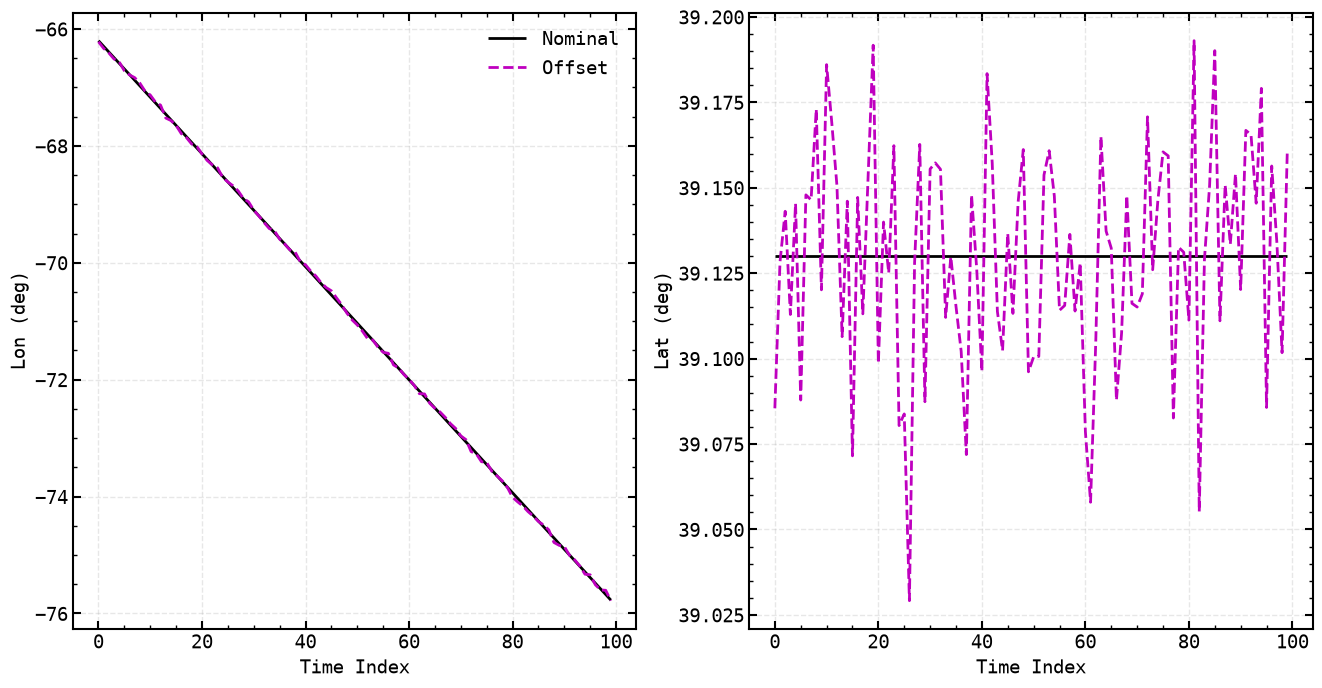

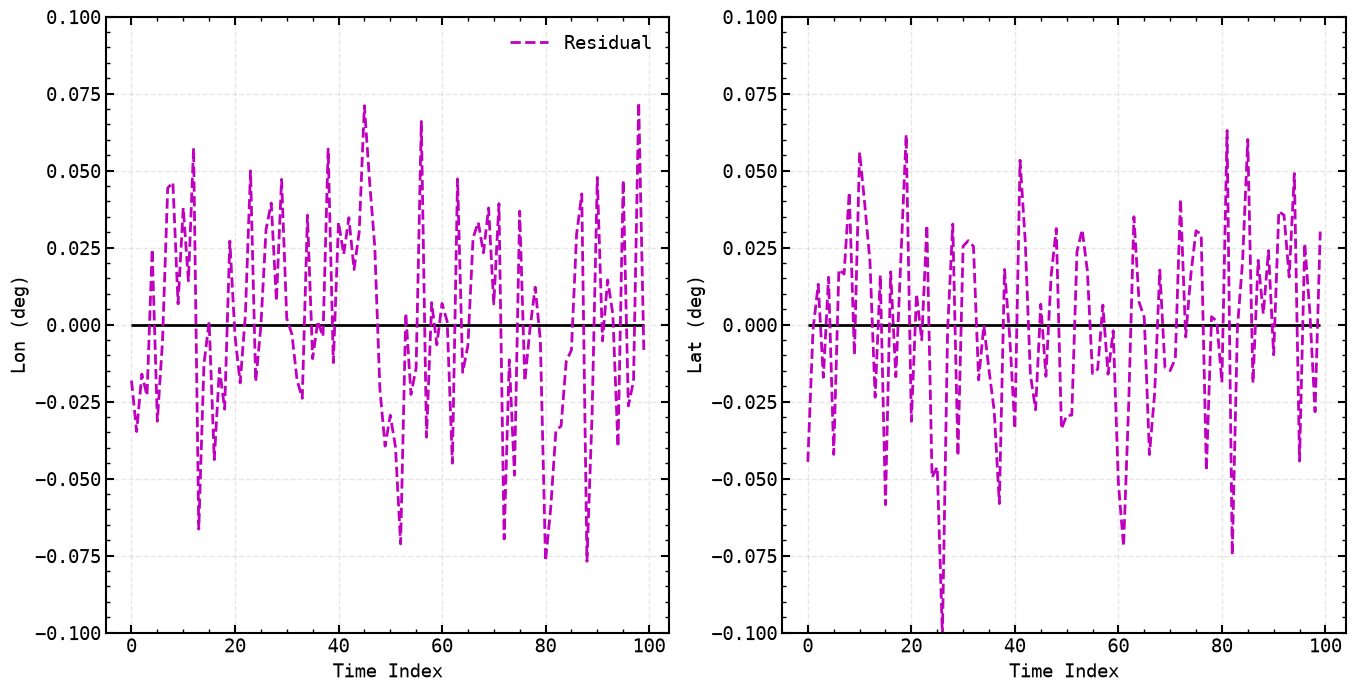

In [83]:
import toast.qarray as qa

data_path = os.path.join(path_to_data, maps_dict["plain_CMB"]["path"], "data", "deep56-0-0_w16.h5")
with h5py.File(data_path, 'r') as f:
    print(f.keys())
    print(f["shared"].keys())
    boresight_arr = np.array(f["shared"]["boresight_azel"])

jitter_data_path = data_path = os.path.join(path_to_data, maps_dict["jitter_CMB"]["path"], "data", "deep56-0-0_w16.h5")
with h5py.File(jitter_data_path, 'r') as f:
    print(f.keys())
    print(f["shared"].keys())
    jitter_arr = np.array(f["shared"]["boresight_azel_jitter"])

# %%
slc = slice(0, 1000, 10)

bquat = np.array(boresight_arr[slc, :])
qbang = np.zeros((3, bquat.shape[0]), dtype=np.float64)
qbang[0], qbang[1], qbang[2] = qa.to_lonlat_angles(bquat)
qbang[0] *= 180.0 / np.pi
qbang[1] *= 180.0 / np.pi

oquat = np.array(jitter_arr[slc, :])
obang = np.zeros((3, oquat.shape[0]), dtype=np.float64)
obang[0], obang[1], obang[2] = qa.to_lonlat_angles(oquat)
obang[0] *= 180.0 / np.pi
obang[1] *= 180.0 / np.pi


fig, axs = plt.subplots(1, 2, figsize=(16,8))
axs[0].plot(qbang[0], label="Nominal")
axs[0].plot(obang[0], label="Offset")
axs[0].legend()
axs[0].set_xlabel("Time Index")
axs[0].set_ylabel("Lon (deg)")

axs[1].plot(qbang[1])
axs[1].plot(obang[1])
axs[1].set_xlabel("Time Index")
axs[1].set_ylabel("Lat (deg)")
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(16,8))
axs[0].plot(np.arange(len(obang[0])), np.zeros_like(obang[0]))
axs[0].plot(obang[0]-qbang[0], label="Residual")
axs[0].set_ylim(-0.1, 0.1)
axs[0].legend()
axs[0].set_xlabel("Time Index")
axs[0].set_ylabel("Lon (deg)")

axs[1].plot(np.arange(len(obang[1])), np.zeros_like(obang[1]))
axs[1].plot(obang[1] - qbang[1])
axs[1].set_ylim(-0.1, 0.1)
axs[1].set_xlabel("Time Index")
axs[1].set_ylabel("Lat (deg)")
plt.show()

# HD Mars Maps

In [ ]:
# Only run this to read the HD sparse maps
# nside, nest, pix, (I, Q, U) = read_sparse(os.path.join(path_to_data, run_path['hd_jitter'], "filterbin_filtered_map.h5"))
# np.savez_compressed("hd_jitter_sparse.npz", nside=nside, nest=nest, pix=pix,
#                     I=I.astype(np.float32), Q=Q.astype(np.float32), U=U.astype(np.float32))

In [ ]:
with np.load("hd_jitter_sparse.npz") as data:
    hd_jitter = {key: data[key] for key in data.files}
with np.load("hd_plain_sparse.npz") as data:
    hd_plain = {key: data[key] for key in data.files}

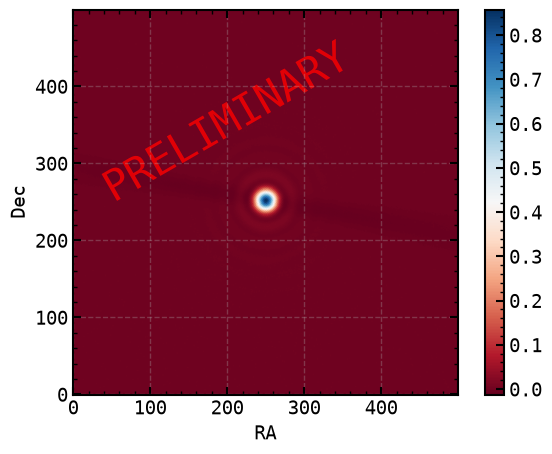

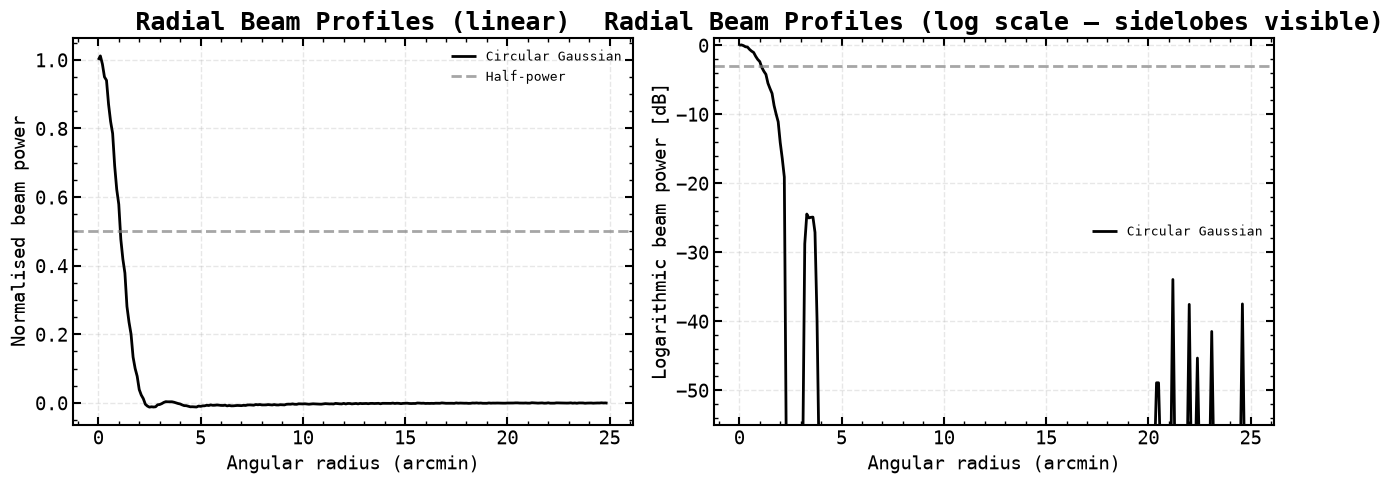

In [ ]:
map_name = "hd_plain"
img = sparse_gnomview(
    hd_plain["nside"], 
    hd_plain["nest"], 
    hd_plain["pix"], 
    hd_plain["I"], 
    maps_dict['plain']['rot_est'], 
    xsize=500, 
    reso=0.1,
    cmap="RdBu",
    )

maps_dict[map_name] = {
    "I_map" : img,
    "rot_est" : maps_dict['plain']['rot_est'],
    "path" : "/shared_home/henachman/data/sim_outputs/Mars/HD_Mars_f090"
}
    # Add a centered text watermark
plt.text(200, 350, 'PRELIMINARY',
        fontsize=30, 
        color='red', 
        alpha=0.8,             # Transparency setting
        ha='center', 
        va='center', 
        rotation=30, 
        zorder=0)              # Places text behind data plots

plt.xlabel("RA")
plt.ylabel("Dec")
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)
plt.show()

r_amin, profile = get_radial_profile(img, 500, 0.1, show=True)
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "radial_profile.png"), dpi=300)
plt.show()

maps_dict[map_name]["profile"] = [r_amin, profile]

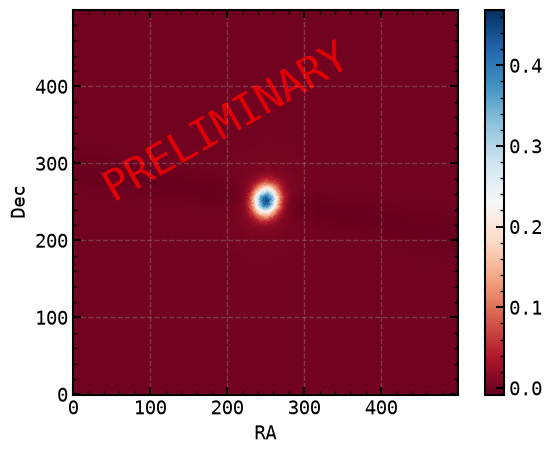

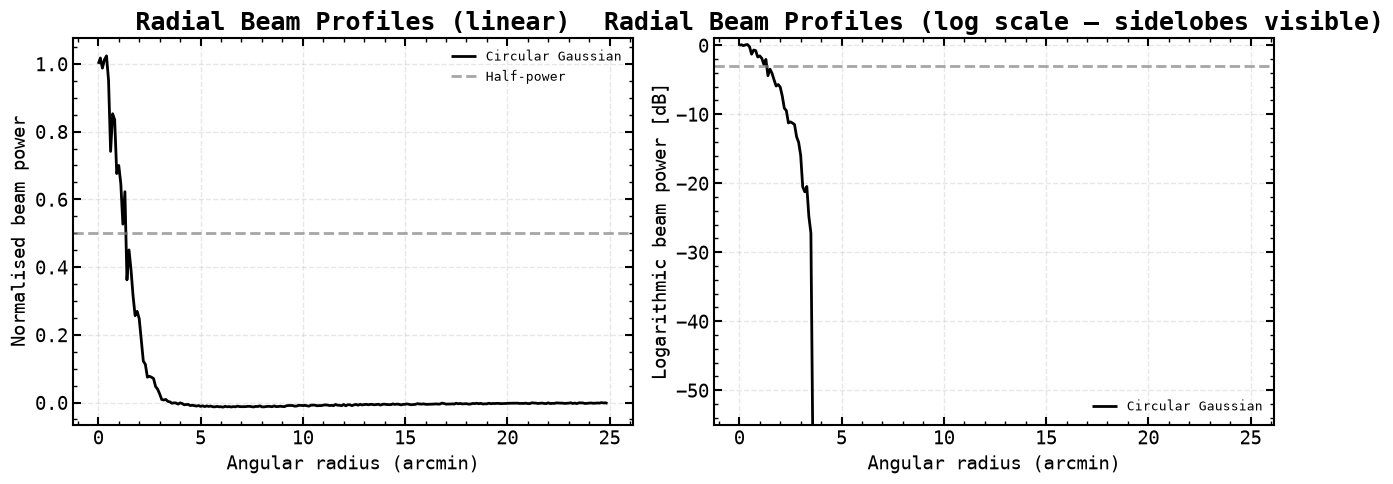

In [ ]:
map_name = "hd_jitter"
img = sparse_gnomview(
    hd_jitter["nside"], 
    hd_jitter["nest"], 
    hd_jitter["pix"], 
    hd_jitter["I"], 
    maps_dict['plain']['rot_est'], 
    xsize=500, 
    reso=0.1,
    cmap="RdBu",
    )

maps_dict[map_name] = {
    "I_map" : img,
    "rot_est" : maps_dict['plain']['rot_est'],
    "path" : "/shared_home/henachman/data/sim_outputs/Mars/HD_Mars_jitter_f090"
}

    # Add a centered text watermark
plt.text(200, 350, 'PRELIMINARY',
        fontsize=30, 
        color='red', 
        alpha=0.8,             # Transparency setting
        ha='center', 
        va='center', 
        rotation=30, 
        zorder=0)  

plt.xlabel("RA")
plt.ylabel("Dec")
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)
plt.show()

r_amin, profile = get_radial_profile(img, 500, 0.1, show=True)
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "radial_profile.png"), dpi=300)
plt.show()


maps_dict[map_name]["profile"] = [r_amin, profile]

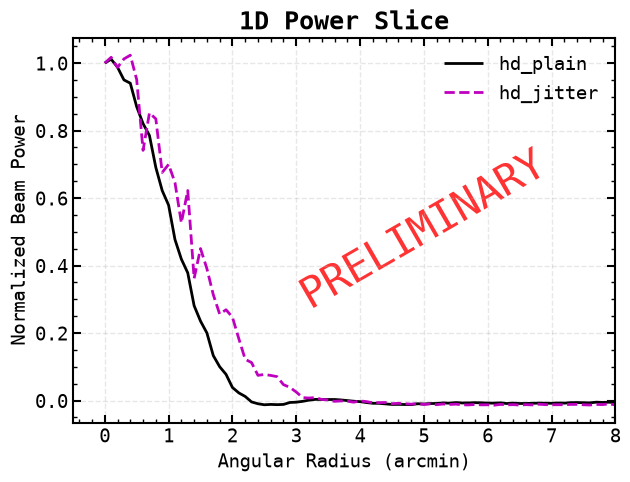

In [ ]:
for map_name in ["hd_plain", "hd_jitter"]: #maps_dict.keys():
    x, y = maps_dict[map_name]["profile"]
    plt.plot(x, y, label=f"{map_name}")
plt.xlim(-0.5, 8)
plt.title("1D Power Slice")
    # Add a centered text watermark
plt.text(5, 0.5, 'PRELIMINARY',
        fontsize=30, 
        color='red', 
        alpha=0.8,             # Transparency setting
        ha='center', 
        va='center', 
        rotation=30, 
        zorder=0)              # Places text behind data plots

plt.ylabel("Normalized Beam Power")
plt.xlabel("Angular Radius (arcmin)")
plt.legend()
plt.show()